# Lab 4 - Task

# 1. Why I selected this competition

### The Titanic competition is appropriate for this lab because:

---
- It is a supervised learning problem with a clearly defined target variable, Survived.

- It includes both numerical and categorical features, allowing us to practice data cleaning, encoding and feature engineering.

- It is suitable for tree-based classification algorithms such as Decision Tree, Random Forest and Gradient Boosting.

- It provides separate training and test datasets, allowing us to validate our models and create a Kaggle submission.

- Its relatively small dataset makes it practical to experiment with multiple models and hyperparameter tuning.

---
# 2. Competition Objective and Evaluation Metric

The goal is to predict the survival outcome of passengers from the Titanic dataset.

| Item | Description |
|---|---|
| Problem type | Binary classification |
| Target variable | `Survived` |
| Class 0 | Did not survive |
| Class 1 | Survived |
| Training data | `train.csv` |
| Test data | `test.csv` |
| Evaluation metric | Accuracy |
| Submission | `PassengerId`, `Survived` |

#### Evaluation Metric: Accuracy measures the proportion of correct predictions:

$$
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
$$

# 3. Load and inspect the competition data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

Training data shape: (891, 12)
Testing data shape: (418, 11)


In [3]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isnull().sum())

Training columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
print(train_df["Survived"].value_counts())

print("\nSurvival percentages:")
print(train_df["Survived"].value_counts(normalize=True) * 100)

Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


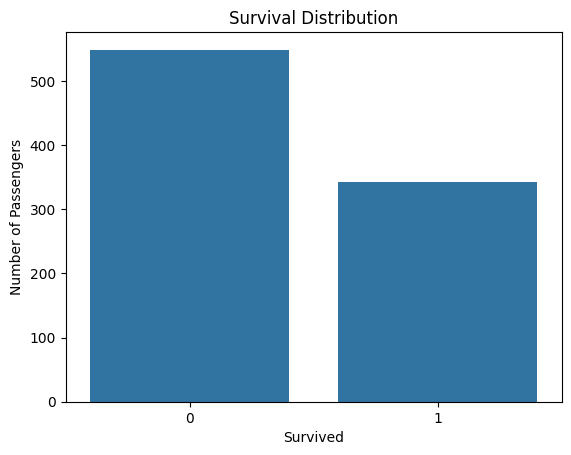

In [8]:
sns.countplot(data=train_df, x="Survived")
plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()

# 4. Data Cleaning and Exploratory Data Analysis (EDA)

In [9]:
missing = train_df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

Cabin       687
Age         177
Embarked      2
dtype: int64


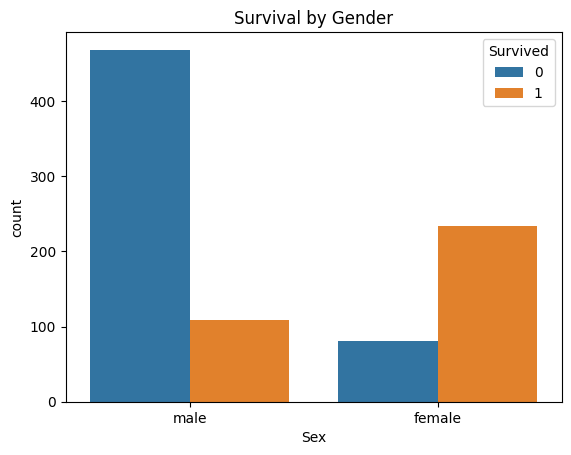

In [10]:
sns.countplot(
    data=train_df,
    x="Sex",
    hue="Survived"
)

plt.title("Survival by Gender")
plt.show()

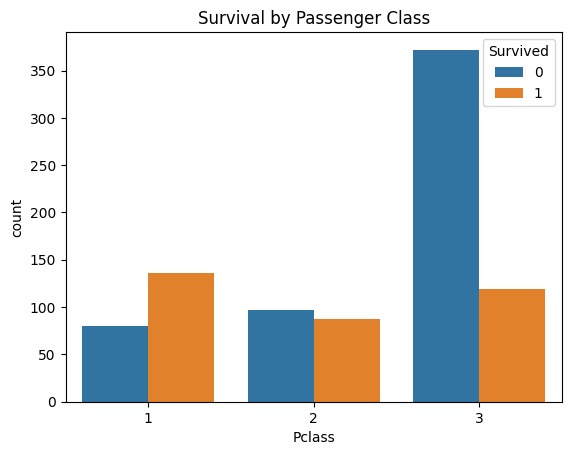

In [11]:
sns.countplot(
    data=train_df,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival by Passenger Class")
plt.show()

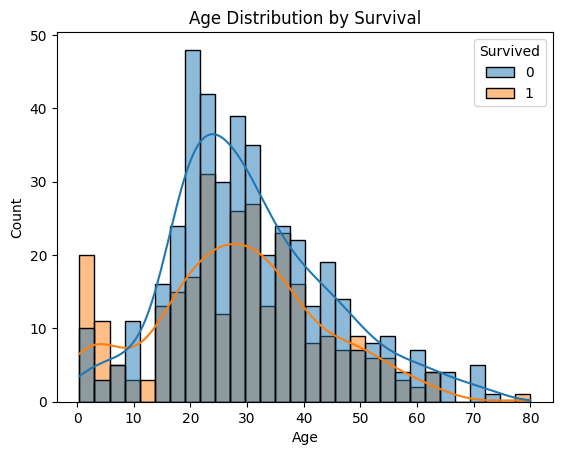

In [12]:
sns.histplot(
    data=train_df,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True
)

plt.title("Age Distribution by Survival")
plt.show()

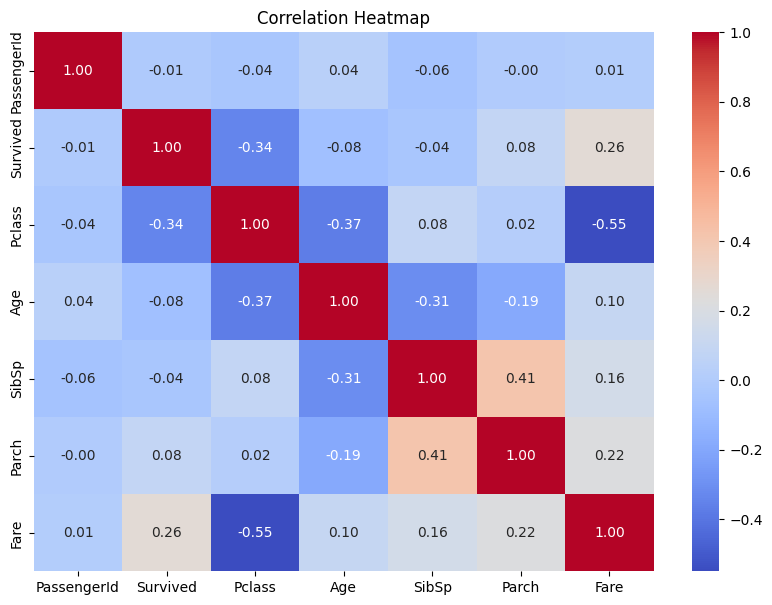

In [13]:
numeric_df = train_df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# 5. Feature Engineering

In [14]:
def feature_engineering(df):

    df = df.copy()

    # Extract title from passenger name
    df["Title"] = df["Name"].str.extract(
        r",\s*([^.]*)\."
    )[0].str.strip()

    # Group uncommon titles
    title_counts = df["Title"].value_counts()

    df["Title"] = df["Title"].where(
        df["Title"].map(title_counts) >= 10,
        "Other"
    )

    # Family size
    df["FamilySize"] = (
        df["SibSp"] + df["Parch"] + 1
    )

    # Is passenger alone?
    df["IsAlone"] = (
        df["FamilySize"] == 1
    ).astype(int)

    # Extract cabin deck
    df["Deck"] = df["Cabin"].str[0].fillna("Unknown")

    # Remove high-cardinality or less useful raw columns
    df = df.drop(
        columns=["PassengerId", "Name", "Ticket", "Cabin"]
    )

    return df

In [15]:
train_fe = feature_engineering(train_df)
test_fe = feature_engineering(test_df)

print(train_fe.head())
print("\nTraining shape:", train_fe.shape)
print("Testing shape:", test_fe.shape)

   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked Title  \
0         0       3    male  22.0      1      0   7.2500        S    Mr   
1         1       1  female  38.0      1      0  71.2833        C   Mrs   
2         1       3  female  26.0      0      0   7.9250        S  Miss   
3         1       1  female  35.0      1      0  53.1000        S   Mrs   
4         0       3    male  35.0      0      0   8.0500        S    Mr   

   FamilySize  IsAlone     Deck  
0           2        0  Unknown  
1           2        0        C  
2           1        1  Unknown  
3           2        0        C  
4           1        1  Unknown  

Training shape: (891, 12)
Testing shape: (418, 11)


In [16]:
X = train_fe.drop(columns=["Survived"])
y = train_fe["Survived"]

X_test = test_fe.copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

X shape: (891, 11)
y shape: (891,)
X_test shape: (418, 11)


# 6. Build a Baseline Model

In [17]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples: 712
Validation samples: 179


In [18]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_preds = baseline.predict(X_val)

baseline_accuracy = accuracy_score(
    y_val,
    baseline_preds
)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.6145251396648045


# 7. Data Preprocessing

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 8. Train Three Tree-Based Models

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

In [21]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

In [22]:
results = []

for name, pipeline in pipelines.items():

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(name, "Accuracy:", accuracy)

Decision Tree Accuracy: 0.7821229050279329
Random Forest Accuracy: 0.8100558659217877
Gradient Boosting Accuracy: 0.8100558659217877


In [23]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(results_df)

               Model  Accuracy
1      Random Forest  0.810056
2  Gradient Boosting  0.810056
0      Decision Tree  0.782123


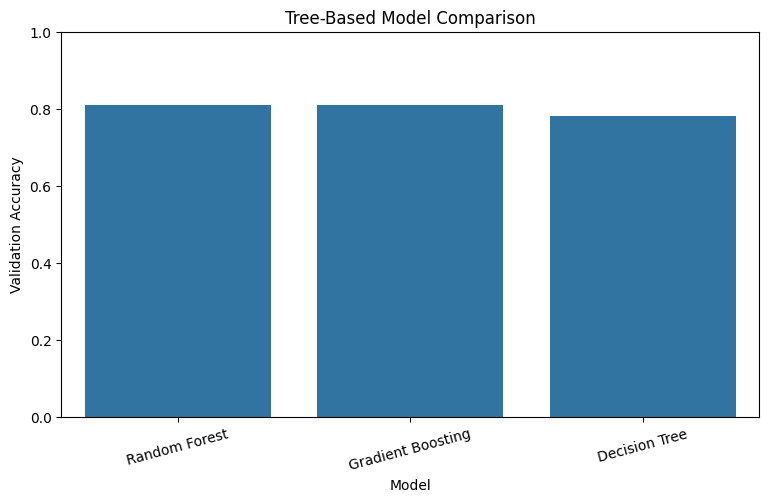

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Tree-Based Model Comparison")
plt.ylim(0, 1)
plt.ylabel("Validation Accuracy")
plt.xticks(rotation=15)
plt.show()

# 9. Compare Models Using Cross-Validation

In [25]:
from sklearn.model_selection import cross_val_score

cv_results = []

for name, pipeline in pipelines.items():

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

    print(name)
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print("Standard deviation:", scores.std())
    print()

Decision Tree
Fold scores: [0.77653631 0.78651685 0.79213483 0.76966292 0.78651685]
Mean accuracy: 0.7822735547046638
Standard deviation: 0.00806473773523679

Random Forest
Fold scores: [0.81005587 0.78089888 0.83707865 0.75842697 0.83707865]
Mean accuracy: 0.8047078023978408
Standard deviation: 0.031090597608443984

Gradient Boosting
Fold scores: [0.83798883 0.80337079 0.84269663 0.80898876 0.85393258]
Mean accuracy: 0.8293955181721173
Standard deviation: 0.019730962433638814



# 10. Tune at Least One Model

In [26]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

In [27]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV Accuracy:")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best CV Accuracy:
0.8287402738106963


In [28]:
best_model = grid_search.best_estimator_

tuned_preds = best_model.predict(X_val)

tuned_accuracy = accuracy_score(
    y_val,
    tuned_preds
)

print("Tuned Random Forest Accuracy:", tuned_accuracy)

Tuned Random Forest Accuracy: 0.8100558659217877


# 11. Evaluate the Final Model

In [29]:
print(
    classification_report(
        y_val,
        tuned_preds,
        target_names=["Did Not Survive", "Survived"]
    )
)

                 precision    recall  f1-score   support

Did Not Survive       0.82      0.89      0.85       110
       Survived       0.80      0.68      0.73        69

       accuracy                           0.81       179
      macro avg       0.81      0.79      0.79       179
   weighted avg       0.81      0.81      0.81       179



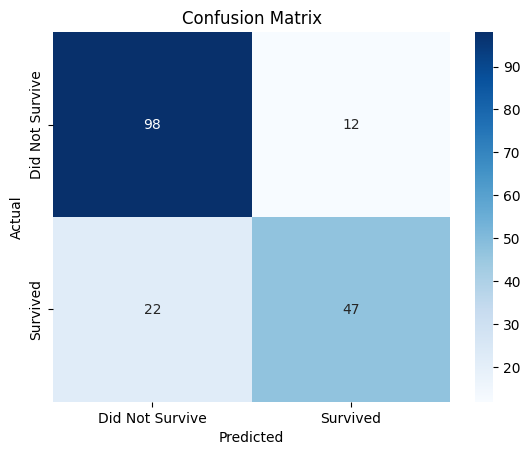

In [30]:
cm = confusion_matrix(y_val, tuned_preds)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 12. Generate the Kaggle Submission File

In [31]:
final_model = grid_search.best_estimator_

final_model.fit(X, y)

print("Final model trained on all training data.")

Final model trained on all training data.


In [32]:
test_predictions = final_model.predict(X_test)

print(test_predictions[:10])

[0 0 0 0 1 0 1 0 1 0]


In [33]:
submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": test_predictions
})

print(submission.head())

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1


In [34]:
submission.to_csv(
    "submission.csv",
    index=False
)

print("Submission file created successfully!")

Submission file created successfully!


In [35]:
print("Submission shape:", submission.shape)

print("\nMissing values:")
print(submission.isnull().sum())

print("\nTarget values:")
print(submission["Survived"].value_counts())

print("\nColumns:")
print(submission.columns.tolist())

Submission shape: (418, 2)

Missing values:
PassengerId    0
Survived       0
dtype: int64

Target values:
Survived
0    265
1    153
Name: count, dtype: int64

Columns:
['PassengerId', 'Survived']


# Explain the leaderboard result

The tuned Random Forest model achieved a validation accuracy of 0.8287 and a public leaderboard accuracy of 0.77990. The difference between these values may be due to differences in the validation and leaderboard samples. The result provides an estimate of how well the model generalizes to unseen passenger records.

# 14. Limitations and Possible Improvements

## Limitations
---
1. Small dataset: The competition's labeled training dataset contains only 891 passengers. The model may not learn all the patterns that affect survival, and a validation score can vary depending on the split.

2. Missing and incomplete information: Many passengers have missing age and cabin details. Imputation can introduce uncertainty, while missing cabin information may conceal potentially useful patterns.

3. Feature engineering assumptions: Grouping rare titles and using family size can simplify the data, but these transformations may not represent every passenger's situation accurately.
---
## Possible improvements

1. Advanced feature engineering: Explore family survival patterns, ticket groups, fare per passenger and more carefully grouped passenger titles. These features may help the models capture relationships that are not represented by the original columns.

2. Broader hyperparameter tuning: Explore additional Random Forest and Gradient Boosting configurations, including different tree depths, learning rates, minimum leaf sizes and the number of estimators. Use cross-validation to assess whether improvements are consistent.

3. Ensemble learning: Combine predictions from multiple models, such as Random Forest and Gradient Boosting, to test whether their different decision boundaries improve validation performance.

4. More robust validation: Repeat stratified cross-validation with multiple random seeds or use repeated stratified cross-validation to assess how sensitive model performance is to the data split.

15. Final Conclusion